In [3]:
%load_ext autoreload
%autoreload 2

import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from src.features import SET_A_TREE, SET_A_LINEAR, SET_A_NO_HOUR
from src.evaluate import evaluate, REF_FRAUD_RATE

PROC = PROJECT_ROOT / "data" / "processed"
train = pd.read_parquet(PROC / "train.parquet")
val = pd.read_parquet(PROC / "val.parquet")   # test.parquet is deliberately not loaded here

y_train, y_val = train["isFraud"], val["isFraud"]
n_pos, n_neg = int(y_train.sum()), int((y_train == 0).sum())
print(train.shape, val.shape, "| train fraud:", n_pos, "| genuine:", n_neg)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


RecursionError: maximum recursion depth exceeded

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from src.features import SET_A_TREE, SET_A_LINEAR, SET_A_NO_HOUR
from src.evaluate import evaluate, REF_FRAUD_RATE

PROC = PROJECT_ROOT / "data" / "processed"
train = pd.read_parquet(PROC / "train.parquet")
val = pd.read_parquet(PROC / "val.parquet")   # test.parquet is deliberately not loaded here

y_train, y_val = train["isFraud"], val["isFraud"]
n_pos, n_neg = int(y_train.sum()), int((y_train == 0).sum())
print(train.shape, val.shape, "| train fraud:", n_pos, "| genuine:", n_neg)

(2646363, 14) (85954, 14) | train fraud: 5621 | genuine: 2640742


In [2]:
for name, part in [("train", train), ("val", val)]:
    capped = part["amount"] == 10_000_000
    fraud_capped = int(part.loc[capped, "isFraud"].sum())
    print(f"{name:<6} rows at exactly 10,000,000: {int(capped.sum()):>6,} | fraud among them: {fraud_capped:>6,}"
          f" | share of all fraud: {fraud_capped / part['isFraud'].sum() * 100:.1f}%")

train  rows at exactly 10,000,000:  3,067 | fraud among them:    167 | share of all fraud: 3.0%
val    rows at exactly 10,000,000:     41 | fraud among them:     38 | share of all fraud: 3.0%


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler


def make_model(name, variant):
    weighted = variant == "class_weight"
    if name == "logreg":
        steps = [("scale", StandardScaler()),
                 ("clf", LogisticRegression(max_iter=300, class_weight="balanced" if weighted else None))]
    elif name == "tree":
        steps = [("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                                class_weight="balanced" if weighted else None,
                                                random_state=42))]
    elif name == "forest":
        steps = [("clf", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                                max_samples=0.3, n_jobs=-1, random_state=42,
                                                class_weight="balanced_subsample" if weighted else None))]
    elif name == "xgboost":
        steps = [("clf", XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, subsample=0.8,
                                       tree_method="hist", n_jobs=-1, random_state=42,
                                       scale_pos_weight=(n_neg / n_pos) if weighted else 1.0))]
    if variant == "undersample":
        return ImbPipeline([("under", RandomUnderSampler(sampling_strategy=0.05, random_state=42))] + steps)
    return Pipeline(steps)

In [4]:
results, val_scores = [], {}

for model_name in ["logreg", "tree", "forest", "xgboost"]:
    cols = SET_A_LINEAR if model_name == "logreg" else SET_A_TREE
    for variant in ["none", "class_weight", "undersample"]:
        t0 = time.time()
        model = make_model(model_name, variant)
        model.fit(train[cols], y_train)
        score = model.predict_proba(val[cols])[:, 1]
        val_scores[(model_name, variant)] = score

        res = evaluate(y_val, score)
        res.update(model=model_name, imbalance=variant, seconds=round(time.time() - t0, 1))
        results.append(res)
        print(f"{model_name:<8} {variant:<13} adjPR={res['pr_auc_adj']:.4f}  ROC={res['roc_auc']:.3f}  ({res['seconds']}s)")

logreg   none          adjPR=0.0764  ROC=0.806  (1.5s)
logreg   class_weight  adjPR=0.0490  ROC=0.818  (1.4s)
logreg   undersample   adjPR=0.0621  ROC=0.812  (0.6s)
tree     none          adjPR=0.2323  ROC=0.862  (5.4s)
tree     class_weight  adjPR=0.2282  ROC=0.859  (5.7s)
tree     undersample   adjPR=0.2118  ROC=0.868  (0.5s)
forest   none          adjPR=0.2574  ROC=0.880  (78.8s)
forest   class_weight  adjPR=0.1942  ROC=0.863  (86.1s)
forest   undersample   adjPR=0.2075  ROC=0.881  (2.8s)
xgboost  none          adjPR=0.2434  ROC=0.873  (33.9s)
xgboost  class_weight  adjPR=0.2363  ROC=0.870  (30.3s)
xgboost  undersample   adjPR=0.2275  ROC=0.876  (2.2s)


In [5]:
res_df = pd.DataFrame(results)
show = ["model", "imbalance", "pr_auc_adj", "roc_auc", "recall@1%FPR", "recall@0.1%FPR", "pr_auc_raw", "seconds"]
print("Random-scorer baselines on val: adjusted PR-AUC = 0.0021, raw PR-AUC = 0.0147\n")
res_df[show].sort_values("pr_auc_adj", ascending=False).reset_index(drop=True).round(4)

Random-scorer baselines on val: adjusted PR-AUC = 0.0021, raw PR-AUC = 0.0147



,model,imbalance,pr_auc_adj,roc_auc,recall@1%FPR,recall@0.1%FPR,pr_auc_raw,seconds
0,forest,none,0.2574,0.8801,0.4438,0.2508,0.4175,78.8
1,xgboost,none,0.2434,0.8733,0.4320,0.2484,0.4067,33.9
2,xgboost,class_weight,0.2363,0.8695,0.4407,0.2366,0.4008,30.3
3,tree,none,0.2323,0.8622,0.4343,0.2215,0.3931,5.4
4,tree,class_weight,0.2282,0.8590,0.4415,0.2381,0.3922,5.7
5,xgboost,undersample,0.2275,0.8762,0.4304,0.2191,0.3974,2.2
6,tree,undersample,0.2118,0.8680,0.4415,0.1820,0.3765,0.5
7,forest,undersample,0.2075,0.8815,0.4335,0.2255,0.4014,2.8
8,forest,class_weight,0.1942,0.8626,0.4430,0.2215,0.3807,86.1
9,logreg,none,0.0764,0.8063,0.3093,0.1108,0.2397,1.5


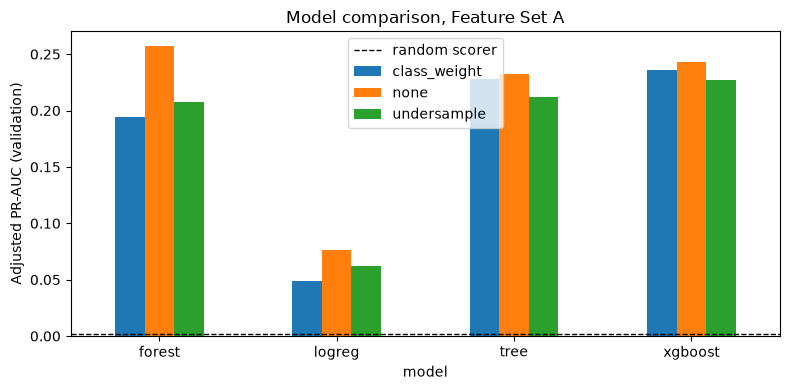

In [6]:
pivot = res_df.pivot(index="model", columns="imbalance", values="pr_auc_adj")
ax = pivot.plot(kind="bar", figsize=(8, 4), rot=0)
ax.axhline(REF_FRAUD_RATE, color="black", linestyle="--", linewidth=1, label="random scorer")
ax.set_ylabel("Adjusted PR-AUC (validation)")
ax.set_title("Model comparison, Feature Set A")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/06_model_comparison_setA.png", dpi=150)
plt.show()

In [7]:
for label, cols in [("with hour", SET_A_TREE), ("without hour", SET_A_NO_HOUR)]:
    m = make_model("xgboost", "none")
    m.fit(train[cols], y_train)
    r = evaluate(y_val, m.predict_proba(val[cols])[:, 1])
    print(f"{label:<13}", {k: round(v, 4) for k, v in r.items() if k in ("pr_auc_adj", "roc_auc", "recall@1%FPR")})

with hour     {'roc_auc': 0.8733, 'pr_auc_adj': 0.2434, 'recall@1%FPR': 0.432}
without hour  {'roc_auc': 0.7992, 'pr_auc_adj': 0.1979, 'recall@1%FPR': 0.2373}


In [8]:
from sklearn.metrics import average_precision_score
from src.evaluate import prevalence_weights, recall_at_fpr

finalists = {
    "forest": val_scores[("forest", "none")],
    "xgboost": val_scores[("xgboost", "none")],
    "tree": val_scores[("tree", "none")],
    "xgb_undersample": val_scores[("xgboost", "undersample")],
}

y = y_val.to_numpy()
n = len(y)
rng = np.random.default_rng(0)
B = 200

boot_pr = {k: [] for k in finalists}
boot_rec = {k: [] for k in finalists}

for _ in range(B):
    idx = rng.integers(0, n, n)
    yb = y[idx]
    w = prevalence_weights(yb)
    for k, s in finalists.items():
        sb = s[idx]
        boot_pr[k].append(average_precision_score(yb, sb, sample_weight=w))
        boot_rec[k].append(recall_at_fpr(yb, sb, 0.01))

def ci(values):
    a = np.array(values)
    return pd.Series({"mean": a.mean(), "2.5%": np.percentile(a, 2.5), "97.5%": np.percentile(a, 97.5)})

print("Adjusted PR-AUC, 95% bootstrap interval")
print(pd.DataFrame({k: ci(v) for k, v in boot_pr.items()}).T.round(4))
print("\nRecall at 1% FPR, 95% bootstrap interval")
print(pd.DataFrame({k: ci(v) for k, v in boot_rec.items()}).T.round(4))

diff = np.array(boot_pr["forest"]) - np.array(boot_pr["xgboost"])
print(f"\nforest minus xgboost (adj PR-AUC): mean {diff.mean():.4f}, "
      f"95% interval [{np.percentile(diff, 2.5):.4f}, {np.percentile(diff, 97.5):.4f}], "
      f"forest ahead in {np.mean(diff > 0) * 100:.0f}% of resamples")

Adjusted PR-AUC, 95% bootstrap interval
                   mean    2.5%   97.5%
forest           0.2575  0.2293  0.2877
xgboost          0.2439  0.2189  0.2737
tree             0.2326  0.2073  0.2603
xgb_undersample  0.2280  0.1987  0.2548

Recall at 1% FPR, 95% bootstrap interval
                   mean    2.5%   97.5%
forest           0.4456  0.4168  0.4742
xgboost          0.4350  0.4078  0.4662
tree             0.4320  0.4035  0.4638
xgb_undersample  0.4317  0.4022  0.4636

forest minus xgboost (adj PR-AUC): mean 0.0135, 95% interval [0.0043, 0.0225], forest ahead in 99% of resamples


In [9]:
keep = (val["amount"] != 10_000_000).to_numpy()

rows = []
for name in [("forest", "none"), ("xgboost", "none"), ("tree", "none")]:
    s = val_scores[name]
    full = evaluate(y_val, s)
    sub = evaluate(y_val[keep], s[keep])
    rows.append({
        "model": name[0],
        "adjPR_all": round(full["pr_auc_adj"], 4), "adjPR_excl10M": round(sub["pr_auc_adj"], 4),
        "rec1%_all": round(full["recall@1%FPR"], 4), "rec1%_excl10M": round(sub["recall@1%FPR"], 4),
    })
print("Validation rows removed:", int((~keep).sum()), "| fraud among them:", int(y_val[~keep].sum()))
pd.DataFrame(rows)

Validation rows removed: 41 | fraud among them: 38


,model,adjPR_all,adjPR_excl10M,rec1%_all,rec1%_excl10M
0,forest,0.2574,0.2416,0.4438,0.4299
1,xgboost,0.2434,0.2275,0.4320,0.4241
2,tree,0.2323,0.2163,0.4343,0.4266


In [10]:
from src.features import SET_B_TREE, SET_B_LINEAR

rows_b = []
for model_name in ["logreg", "tree", "xgboost"]:
    cols = SET_B_LINEAR if model_name == "logreg" else SET_B_TREE
    m = make_model(model_name, "none")
    m.fit(train[cols], y_train)
    r = evaluate(y_val, m.predict_proba(val[cols])[:, 1])
    rows_b.append({"model": model_name, "set": "B (+old balance)",
                   "pr_auc_adj": r["pr_auc_adj"], "roc_auc": r["roc_auc"], "recall@1%FPR": r["recall@1%FPR"]})

setB = pd.DataFrame(rows_b)
setA = (res_df[(res_df["imbalance"] == "none") & res_df["model"].isin(["logreg", "tree", "xgboost"])]
        [["model", "pr_auc_adj", "roc_auc", "recall@1%FPR"]].assign(set="A (strict)"))

pd.concat([setA, setB]).sort_values(["model", "set"]).reset_index(drop=True).round(4)

,model,pr_auc_adj,roc_auc,recall@1%FPR,set
0,logreg,0.0764,0.8063,0.3093,A (strict)
1,logreg,0.9975,0.9976,0.9976,B (+old balance)
2,tree,0.2323,0.8622,0.4343,A (strict)
3,tree,1.0000,1.0000,1.0000,B (+old balance)
4,xgboost,0.2434,0.8733,0.4320,A (strict)
5,xgboost,0.9999,1.0000,1.0000,B (+old balance)


## Decisions (Phase 4A): first model comparison, Feature Set A, validation set
- Adjusted PR-AUC (random scorer = 0.0021): forest/none 0.257, xgboost/none 0.243, xgboost/class_weight 0.236, tree/none 0.232, xgboost/undersample 0.228, forest/undersample 0.208, forest/class_weight 0.194, logreg 0.049-0.076.
- Tree-based models are in a narrow band (0.23-0.26) with near-identical recall@1%FPR (0.43-0.44): with only three features, the information content, not the algorithm, is the ceiling.
- Imbalance handling did not beat the natural distribution for any model; undersampling trains ~15x faster for ~0.016 lower adjusted PR-AUC (XGBoost).
- Hour ablation (XGBoost): recall@1%FPR 0.432 with hour vs 0.237 without; ROC-AUC 0.873 vs 0.799. Hour is a major contributor and likely exaggerated by the simulator (genuine traffic near zero at night, fraud flat).
- Amount = 10,000,000: train 3,067 rows (167 fraud, 5.4%); val 41 rows (38 fraud). Affects at most 3.0% of validation fraud; robustness check in 4B.
- Provisional finalist: XGBoost (statistically tied with forest pending bootstrap; faster, native imbalance support, SHAP-friendly).
- Practical reading at training prevalence (per 100,000 transactions, ~212 fraud, forest): 0.1% FPR -> ~53 frauds caught, ~35% of alerts real; 1% FPR -> ~94 caught, ~9% of alerts real.

In [11]:
steps_val = val["step"].to_numpy()
order = np.argsort(steps_val, kind="stable")
_, starts = np.unique(steps_val[order], return_index=True)
groups = np.split(order, starts[1:])          # one array of row positions per hour (step)
print("Hours in validation:", len(groups))

rng = np.random.default_rng(1)
d_pr, d_rec = [], []
for _ in range(200):
    pick = rng.integers(0, len(groups), len(groups))
    idx = np.concatenate([groups[i] for i in pick])
    yb = y[idx]
    w = prevalence_weights(yb)
    pf = average_precision_score(yb, finalists["forest"][idx], sample_weight=w)
    px = average_precision_score(yb, finalists["xgboost"][idx], sample_weight=w)
    d_pr.append(pf - px)
    d_rec.append(recall_at_fpr(yb, finalists["forest"][idx], 0.01) - recall_at_fpr(yb, finalists["xgboost"][idx], 0.01))

for name, d in [("adj PR-AUC", d_pr), ("recall@1%FPR", d_rec)]:
    d = np.array(d)
    print(f"forest minus xgboost, {name}: mean {d.mean():.4f}, 95% [{np.percentile(d, 2.5):.4f}, {np.percentile(d, 97.5):.4f}], "
          f"forest ahead in {np.mean(d > 0) * 100:.0f}%")

Hours in validation: 120
forest minus xgboost, adj PR-AUC: mean 0.0138, 95% [0.0015, 0.0242], forest ahead in 99%
forest minus xgboost, recall@1%FPR: mean 0.0118, 95% [-0.0023, 0.0280], forest ahead in 92%
